# Employee Churn: XGBoost + Logistic Regression blend

**Question:** does averaging the final XGBoost model with Logistic Regression give HR a better churn list?

This notebook reproduces **every output of `xgboost_final.ipynb`, in the same order**, for the blend:

| Kept from xgboost_final (copied unchanged) | Added for the blend |
|---|---|
| Data cleaning, folds, clue columns, preprocessing | Logistic Regression (the project's standard one: median fill, scaling, one-hot, `class_weight="balanced"`) |
| Optuna search, 300 trials per outer fold, PR-AUC objective | Platt scaling of both models' chances, learned on inner predictions |
| 5-seed XGBoost (the final model = the blend's XGB part) | Blend weight on XGBoost, 0 to 1 in steps of 0.05, chosen by inner PR-AUC |
| F1-best cut-off from `CUTOFF_CV` training-part predictions | The same F1-best cut-off rule, applied to the blended chances |

The blend recipe is the "XGBoost + LR · weighted average" from `xgboost_best.ipynb`, the only combination that won there
on training-only evidence. **Expected:** F1 **0.368**, ROC-AUC **0.747**, PR-AUC **0.324** (xgboost_best's numbers).

**Honesty rule:** every choice (XGB settings, Platt scaling, blend weight, cut-off, cost cut-offs) uses training-part
predictions only. Every chart and score uses outer test-fold predictions only.

Charts go to `charts_xgb_blend/` with a `_blend` suffix. Runtime ≈ 7 minutes on 15 cores.

## Step 1: Setup

A fixed random seed and fixed trial counts make every run give the **same numbers**.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import optuna
import joblib
from joblib import Parallel, delayed
from scipy.stats import spearmanr

from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
import xgboost as xgb
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42                     # same seed as every notebook in the project
QUICK = os.environ.get("XGB_QUICK") == "1"     # quick test run only; numbers will NOT match
N_TRIALS = 20 if QUICK else 300       # Optuna tries per search (300 = the winning recipe)
N_SEEDS = 5                           # copies averaged in the XGB part (= the final model)
N_JOBS_FOLDS = 5                      # outer folds tuned side by side
DATA = os.environ.get("CHURN_DATA", "employee_churn_ecommerce_retail_5000_10cols.csv")
OUT = "charts_xgb_blend"
os.makedirs(OUT, exist_ok=True)

BLUE, PURPLE, YELLOW, GREY = "#1D4ED8", "#7E22CE", "#FACC15", "#6B7280"
sns.set_theme(style="whitegrid")
NOTEBOOK_START = time.time()

def save(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)
    plt.show()

print(f"Tools loaded ✓ | xgboost {xgb.__version__} | trials {N_TRIALS} | seeds {N_SEEDS} | quick mode: {QUICK}")

Tools loaded ✓ | xgboost 3.4.1 | trials 300 | seeds 5 | quick mode: False


## Step 2: Load and clean the data

- `churn` = 1 if `termination_date` is filled in (the person left).
- 10 fixed rules blank out impossible values. Each rule looks at **one row only**, so it is safe before splitting.
- `employee_id` is dropped: its year is **not** a hire year (1,220 people have more tenure than it allows),
  and it might have been recorded after people left, which would leak the answer.

In [2]:
raw = pd.read_csv(DATA)
raw["churn"] = raw["termination_date"].notna().astype(int)
df = raw.drop(columns=["employee_id", "termination_date"]).copy()
EDITS = []

def blank_if(rule, col, mask):
    mask = mask.fillna(False)
    df.loc[mask, col] = np.nan
    EDITS.append((rule, int(mask.sum())))

blank_if("tenure > age − 16", "years_at_company", df["years_at_company"] > df["age"] - 16)
blank_if("age outside 16–80", "age", (df["age"] < 16) | (df["age"] > 80))
blank_if("job_satisfaction outside 1–100", "job_satisfaction",
         (df["job_satisfaction"] < 1) | (df["job_satisfaction"] > 100))
blank_if("performance_rating outside 1–5", "performance_rating",
         (df["performance_rating"] < 1) | (df["performance_rating"] > 5))
blank_if("monthly_salary ≤ 0", "monthly_salary", df["monthly_salary"] <= 0)
blank_if("overtime < 0 or > 200 h", "overtime_hours_per_month",
         (df["overtime_hours_per_month"] < 0) | (df["overtime_hours_per_month"] > 200))
blank_if("years_at_company < 0", "years_at_company", df["years_at_company"] < 0)
for c in ["department", "job_level"]:
    tidy = df[c].str.strip().str.title().where(df[c].notna())
    EDITS.append((f"tidy spelling of {c}", int((tidy.fillna("§") != df[c].fillna("§")).sum())))
    df[c] = tidy
dups = df.duplicated()
df = df[~dups].reset_index(drop=True)
EDITS.append(("duplicate rows removed", int(dups.sum())))

print(pd.DataFrame(EDITS, columns=["Cleaning rule", "Cells / rows changed"]).to_string(index=False))

X = df.drop(columns=["churn"])
y = df["churn"]
number_cols = X.select_dtypes("number").columns.tolist()
text_cols = X.select_dtypes(exclude="number").columns.tolist()
if not QUICK:
    assert len(X) == 5000 and y.sum() == 613, "rows or leavers changed!"
print(f"\nRows: {len(X):,} | leavers: {y.sum()} ({y.mean():.1%}) | clue columns: {X.shape[1]}")

                 Cleaning rule  Cells / rows changed
             tenure > age − 16                     0
             age outside 16–80                     0
job_satisfaction outside 1–100                     0
performance_rating outside 1–5                     0
            monthly_salary ≤ 0                     0
       overtime < 0 or > 200 h                     0
          years_at_company < 0                     0
   tidy spelling of department                     0
    tidy spelling of job_level                     0
        duplicate rows removed                     0

Rows: 5,000 | leavers: 613 (12.3%) | clue columns: 8


## Step 3: Folds and scoring tools

- **5 outer folds** (stratified, seed 42): the same test folds as every notebook, used only for reporting.
- **Inner 3-fold CV** (seed 42): Optuna tunes on it, inside each training part.
- **Cut-off CV** (5 folds, seed 1042): predictions on the training part, used to pick the F1-best cut-off.
- The cut-off is **not 0.5**: with only 12% leavers the model rarely gives anyone more than 50%.

In [3]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(folds.split(X, y))
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
CUTOFF_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1000)

METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
METRIC_LABELS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

def cv_metrics(p, thr):
    # Score out-of-fold chances p on each outer fold, each fold at its own cut-off.
    out = {m: [] for m in METRICS}
    for (_, te), t in zip(outer_splits, thr):
        yt, pt = y.iloc[te], p[te]
        pred = (pt >= t).astype(int)
        out["accuracy"].append(accuracy_score(yt, pred))
        out["precision"].append(precision_score(yt, pred, zero_division=0))
        out["recall"].append(recall_score(yt, pred))
        out["f1"].append(f1_score(yt, pred))
        out["roc_auc"].append(roc_auc_score(yt, pt))
        out["pr_auc"].append(average_precision_score(yt, pt))
    return {m: np.array(v) for m, v in out.items()}

def best_threshold(y_true, p):
    # The cut-off with the highest F1 on these (training-only) predictions.
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])])

def inner_oof(model, X_tr, y_tr, cv):
    # Chances for a training part from inner folds (never touches the outer test part).
    return cross_val_predict(model, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]

def fmt(a):
    return f"{np.mean(a):.3f} ± {np.std(a):.3f}"

print("Test fold sizes:", [len(te) for _, te in outer_splits],
      "| leavers per fold:", [int(y.iloc[te].sum()) for _, te in outer_splits])

Test fold sizes: [1000, 1000, 1000, 1000, 1000] | leavers per fold: [122, 122, 123, 123, 123]


## Step 4: The model recipe

**Pipeline** (everything learned is learned in `fit()`, so it only ever sees training data):

1. **Clue columns** (Optuna switches each on or off): overtime × dissatisfaction, salary vs level median,
   salary vs department median, tenure ÷ age, tenure bucket, satisfaction × performance.
2. **Cleaning:** blank numbers → median (optionally with "was blank" flags);
   departments and levels → XGBoost's native categories or one-hot columns.
3. **XGBoost**, with `scale_pos_weight` to give leavers more weight.
4. **5-seed averaging:** 5 copies with seeds 42–46, chances averaged. This was the only XGBoost upgrade that passed.

**Search:** Optuna (TPE sampler + median pruning) tries settings and keeps the best **mean PR-AUC over 3 inner folds**.

In [4]:
CLUES = ["ot_x_dissat", "salary_vs_level", "salary_vs_dept", "tenure_ratio", "tenure_bucket", "sat_x_perf"]

class ChurnFeatures(BaseEstimator, TransformerMixin):
    # Adds the switched-on clue columns. Medians and category lists are learned in fit().

    def __init__(self, ot_x_dissat=False, salary_vs_level=False, salary_vs_dept=False,
                 tenure_ratio=False, tenure_bucket=False, sat_x_perf=False, native_cat=False):
        self.ot_x_dissat = ot_x_dissat
        self.salary_vs_level = salary_vs_level
        self.salary_vs_dept = salary_vs_dept
        self.tenure_ratio = tenure_ratio
        self.tenure_bucket = tenure_bucket
        self.sat_x_perf = sat_x_perf
        self.native_cat = native_cat

    def fit(self, X, y=None):
        self.level_median_ = X.groupby("job_level")["monthly_salary"].median()
        self.dept_median_ = X.groupby("department")["monthly_salary"].median()
        self.salary_median_ = X["monthly_salary"].median()
        self.categories_ = {c: sorted(X[c].dropna().unique()) for c in text_cols}
        return self

    def transform(self, X):
        X = X.copy()
        sal = X["monthly_salary"]
        if self.ot_x_dissat:
            X["ot_x_dissat"] = X["overtime_hours_per_month"] * (100 - X["job_satisfaction"])
        if self.salary_vs_level:
            X["salary_vs_level"] = sal / X["job_level"].map(self.level_median_).astype(float).fillna(self.salary_median_)
        if self.salary_vs_dept:
            X["salary_vs_dept"] = sal / X["department"].map(self.dept_median_).astype(float).fillna(self.salary_median_)
        if self.tenure_ratio:
            X["tenure_ratio"] = X["years_at_company"] / X["age"]
        if self.tenure_bucket:
            X["tenure_bucket"] = pd.cut(X["years_at_company"], [-np.inf, 1, 2, 4, 7, np.inf], labels=False)
        if self.sat_x_perf:
            X["sat_x_perf"] = X["job_satisfaction"] * X["performance_rating"]
        if self.native_cat:
            for c in text_cols:
                X[c] = pd.Categorical(X[c], categories=self.categories_[c])
        return X


def make_xgb_pipe(impute=True, add_indicator=False, native_cat=False, seed=RANDOM_STATE, **params):
    # clues → cleaning → XGBoost
    clues = {f: params.pop(f, False) for f in CLUES}
    numbers = SimpleImputer(strategy="median", add_indicator=add_indicator) if impute else "passthrough"
    text = "passthrough" if native_cat else Pipeline([
        ("fill_blanks", SimpleImputer(strategy="most_frequent")),
        ("to_numbers", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    cleaning = ColumnTransformer([
        ("numbers", numbers, make_column_selector(dtype_include="number")),
        ("text", text, make_column_selector(dtype_exclude="number")),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    model = XGBClassifier(**params, enable_categorical=True, tree_method="hist",
                          eval_metric="logloss", random_state=seed, n_jobs=1)
    return Pipeline([("features", ChurnFeatures(**clues, native_cat=native_cat)),
                     ("prep", cleaning), ("model", model)])


class SeedAvgXGB(ClassifierMixin, BaseEstimator):
    # Average of n_seeds copies of the same recipe (seeds 42, 43, ...).

    def __init__(self, params=None, n_seeds=N_SEEDS):
        self.params = params
        self.n_seeds = n_seeds

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = [make_xgb_pipe(**dict(self.params), seed=RANDOM_STATE + i).fit(X, y)
                        for i in range(self.n_seeds)]
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def suggest_params(trial, fixed=None):
    # The search space: XGBoost settings + on/off switches (a switch in `fixed` is not searched).
    fixed = fixed or {}
    switch = lambda name: fixed[name] if name in fixed else trial.suggest_categorical(name, [True, False])
    p = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 20),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1.0, 7.2),
        max_delta_step=trial.suggest_int("max_delta_step", 0, 10),
        impute=switch("impute"),
        native_cat=switch("native_cat"),
    )
    if p["impute"]:
        p["add_indicator"] = switch("add_indicator")
    for f in CLUES:
        p[f] = switch(f)
    return p


def tune_xgb(X_tr, y_tr, fixed=None):
    # Optuna on the training part only: mean PR-AUC over 3 inner folds, with pruning.
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        params = suggest_params(trial, fixed)
        aps = []
        for step, (a, b) in enumerate(inner_cv.split(X_tr, y_tr)):
            m = make_xgb_pipe(**params).fit(X_tr.iloc[a], y_tr.iloc[a])
            aps.append(average_precision_score(y_tr.iloc[b], m.predict_proba(X_tr.iloc[b])[:, 1]))
            trial.report(np.mean(aps), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(aps))
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0))
    study.optimize(objective, n_trials=N_TRIALS)
    return study

print("Model recipe ready ✓")

Model recipe ready ✓


### The Logistic Regression part and the blend

- **LR** is the main notebook's Logistic Regression, unchanged.
- **Platt scaling:** the two models put their chances on different scales (LR's balanced weights push chances up), so
  each model's chances are first mapped to real leaver rates with a one-line logistic fit on `logit(chance)`,
  learned on **inner** (training-part) predictions.
- **Blend:** `w × XGB + (1 − w) × LR`, both after Platt scaling. `w` is picked from 0, 0.05, …, 1 by the best **inner** PR-AUC.

**Example:** XGB says 0.18 and LR 0.30 (after scaling), w = 0.6 → 0.6 × 0.18 + 0.4 × 0.30 = **0.228**.

In [5]:
prep_lr = ColumnTransformer([
    ("numbers", Pipeline([("fill_blanks", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), number_cols),
    ("text", Pipeline([("fill_blanks", SimpleImputer(strategy="most_frequent")),
                       ("to_numbers", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])
LR = Pipeline([("prep", prep_lr), ("model", LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))])

W_GRID = np.round(np.arange(0, 1.0001, 0.05), 2)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def platt_fit(score, y_true):
    # Maps a model's chances to real leaver rates; fit on inner (training-part) predictions only.
    return LogisticRegression(C=1e6).fit(logit(score)[:, None], y_true)

def platt_apply(scaler, score):
    return scaler.predict_proba(logit(score)[:, None])[:, 1]

def fit_blend(y_true, xgb_in, lr_in):
    # Platt scalers, blend weight and cut-off, all from inner (training-part) predictions.
    px, pl = platt_fit(xgb_in, y_true), platt_fit(lr_in, y_true)
    xs, ls = platt_apply(px, xgb_in), platt_apply(pl, lr_in)
    w = float(max(W_GRID, key=lambda w: average_precision_score(y_true, w * xs + (1 - w) * ls)))
    b_in = w * xs + (1 - w) * ls
    return dict(px=px, pl=pl, w=w, b_in=b_in, thr=best_threshold(y_true, b_in))

def blend_predict(b, xgb_p, lr_p):
    return b["w"] * platt_apply(b["px"], xgb_p) + (1 - b["w"]) * platt_apply(b["pl"], lr_p)

print("LR and blend tools ready ✓")

LR and blend tools ready ✓


## Step 5: Honest score with nested 5-fold cross-validation

For each of the 5 outer folds:
1. Lock away the 1,000 test employees.
2. On the other 4,000, Optuna tries 300 settings (scored on 3 inner folds), exactly as in xgboost_final.
3. Get `CUTOFF_CV` predictions on the training part from the 5-seed XGBoost and from LR; learn the Platt scaling,
   the blend weight and the F1-best cut-off from them.
4. Train both models on all 4,000 and predict the locked 1,000 **once**.

The same folds also give the three comparison models: the **final model** (5-seed XGBoost, = xgboost_final),
**XGB alone** (one seed, same settings) and **LR alone**, each with its own F1-best cut-off from training predictions.

In [6]:
MODELS = {"blend": "XGB + LR blend", "final": "Final model (XGB, 5 seeds)",
          "xgb1": "XGB alone (1 seed)", "lr": "LR alone"}

def run_fold(i):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tr, te = outer_splits[i]
    X_tr, y_tr = X.iloc[tr], y.iloc[tr]
    study = tune_xgb(X_tr, y_tr)
    models = {"final": SeedAvgXGB(study.best_params), "xgb1": SeedAvgXGB(study.best_params, n_seeds=1),
              "lr": clone(LR)}
    inner = {k: inner_oof(m, X_tr, y_tr, CUTOFF_CV) for k, m in models.items()}
    test = {k: m.fit(X_tr, y_tr).predict_proba(X.iloc[te])[:, 1] for k, m in models.items()}
    thr = {k: best_threshold(y_tr, inner[k]) for k in models}
    b = fit_blend(y_tr, inner["final"], inner["lr"])
    inner["blend"], test["blend"], thr["blend"] = b["b_in"], blend_predict(b, test["final"], test["lr"]), b["thr"]
    return dict(params=study.best_params, inner=inner, test=test, thr=thr, w=b["w"])

t0 = time.time()
runs = Parallel(n_jobs=N_JOBS_FOLDS)(delayed(run_fold)(i) for i in range(5))
fold_params = [r["params"] for r in runs]
fold_w = [r["w"] for r in runs]
oof, fold_thr, scores = {}, {}, {}
for k in MODELS:
    oof[k] = np.zeros(len(y))
    for (_, te), r in zip(outer_splits, runs):
        oof[k][te] = r["test"][k]
    fold_thr[k] = [r["thr"][k] for r in runs]
    scores[k] = cv_metrics(oof[k], fold_thr[k])

print(f"Nested CV: {(time.time() - t0) / 60:.1f} min")
print("Blend weight on XGBoost per fold:", fold_w)
print("Cut-off per fold:", [round(t, 3) for t in fold_thr["blend"]], f"(mean {np.mean(fold_thr['blend']):.3f})")
print("F1 per fold:     ", [round(float(v), 4) for v in scores["blend"]["f1"]])
print()
for m, lab in zip(METRICS, METRIC_LABELS):
    print(f"  {lab:10} {fmt(scores['blend'][m])}")

print("\nSame folds, every model (mean ± std over the 5 test folds):")
table = pd.DataFrame({MODELS[k]: {lab: fmt(scores[k][m]) for m, lab in zip(METRICS, METRIC_LABELS)}
                      | {"Mean cut-off": f"{np.mean(fold_thr[k]):.3f}"} for k in MODELS}).T
print(table.to_string())

if not QUICK:
    for k, expected in [("final", {"f1": 0.363, "roc_auc": 0.741, "pr_auc": 0.327}),
                        ("blend", {"f1": 0.368, "roc_auc": 0.747, "pr_auc": 0.324})]:
        got = {m: round(float(scores[k][m].mean()), 3) for m in expected}
        src_nb = "xgboost_final" if k == "final" else "xgboost_best's blend"
        print(f"\n✓ {MODELS[k]} matches {src_nb}" if got == expected
              else f"\n⚠ {MODELS[k]} differs from {src_nb} {expected}: got {got}")

Nested CV: 2.1 min
Blend weight on XGBoost per fold: [0.1, 0.4, 1.0, 0.0, 0.4]
Cut-off per fold: [0.194, 0.175, 0.161, 0.188, 0.169] (mean 0.177)
F1 per fold:      [0.3724, 0.3779, 0.3708, 0.3354, 0.3855]

  Accuracy   0.792 ± 0.014
  Precision  0.295 ± 0.017
  Recall     0.494 ± 0.044
  F1         0.368 ± 0.017
  ROC-AUC    0.747 ± 0.012
  PR-AUC     0.324 ± 0.020

Same folds, every model (mean ± std over the 5 test folds):
                                 Accuracy      Precision         Recall             F1        ROC-AUC         PR-AUC Mean cut-off
XGB + LR blend              0.792 ± 0.014  0.295 ± 0.017  0.494 ± 0.044  0.368 ± 0.017  0.747 ± 0.012  0.324 ± 0.020        0.177
Final model (XGB, 5 seeds)  0.787 ± 0.012  0.287 ± 0.012  0.496 ± 0.055  0.363 ± 0.019  0.741 ± 0.012  0.327 ± 0.020        0.224
XGB alone (1 seed)          0.792 ± 0.017  0.289 ± 0.021  0.473 ± 0.051  0.358 ± 0.020  0.740 ± 0.012  0.324 ± 0.020        0.229
LR alone                    0.796 ± 0.017  0.297 ± 

## Step 6: Confusion matrix (counting people)

Every employee is predicted once, by the model of the fold where they were in the test part,
at that fold's own cut-off. The blend is on the left, the final model on the right.

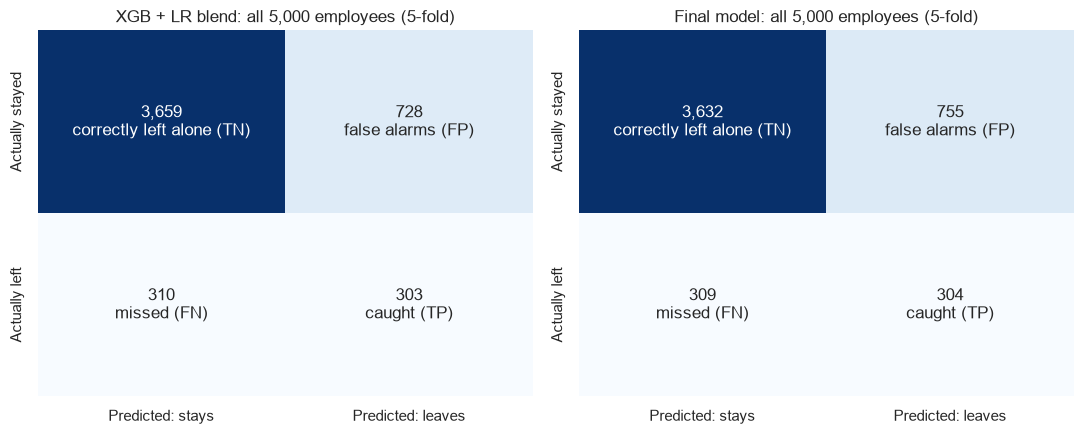

XGB + LR blend: caught 303 of 613 leavers (49.4%) | missed 310 | false alarms 728
  Precision 29.4% | false alarms per leaver caught 2.40 | TN 3,659
Final model (XGB, 5 seeds): caught 304 of 613 leavers (49.6%) | missed 309 | false alarms 755
  Precision 28.7% | false alarms per leaver caught 2.48 | TN 3,632


In [7]:
def pooled_cm(k):
    pred = np.zeros(len(y), dtype=int)
    for (_, te), t in zip(outer_splits, fold_thr[k]):
        pred[te] = (oof[k][te] >= t).astype(int)
    return confusion_matrix(y, pred).ravel()

def draw_cm(ax, k, title):
    tn, fp, fn, tp = pooled_cm(k)
    sns.heatmap([[tn, fp], [fn, tp]], annot=[[f"{tn:,}\ncorrectly left alone (TN)", f"{fp:,}\nfalse alarms (FP)"],
                                             [f"{fn:,}\nmissed (FN)", f"{tp:,}\ncaught (TP)"]],
                fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted: stays", "Predicted: leaves"],
                yticklabels=["Actually stayed", "Actually left"])
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
draw_cm(axes[0], "blend", f"XGB + LR blend: all {len(y):,} employees (5-fold)")
draw_cm(axes[1], "final", f"Final model: all {len(y):,} employees (5-fold)")
save("01_confusion_matrix_blend")

for k in ["blend", "final"]:
    tn, fp, fn, tp = pooled_cm(k)
    print(f"{MODELS[k]}: caught {tp} of {tp + fn} leavers ({tp / (tp + fn):.1%}) | missed {fn} | false alarms {fp}")
    print(f"  Precision {tp / (tp + fp):.1%} | false alarms per leaver caught {fp / tp:.2f} | TN {tn:,}")

## Step 7: ROC and precision-recall curves

Drawn **per fold** (each fold's model has its own probability scale), then averaged; the blend and the final model
get a ± 1 std band. The **dot** on each curve is the chosen cut-off: the mean over the 5 test folds of the
(false-alarm rate, catch rate) or (recall, precision) reached at that fold's own cut-off.

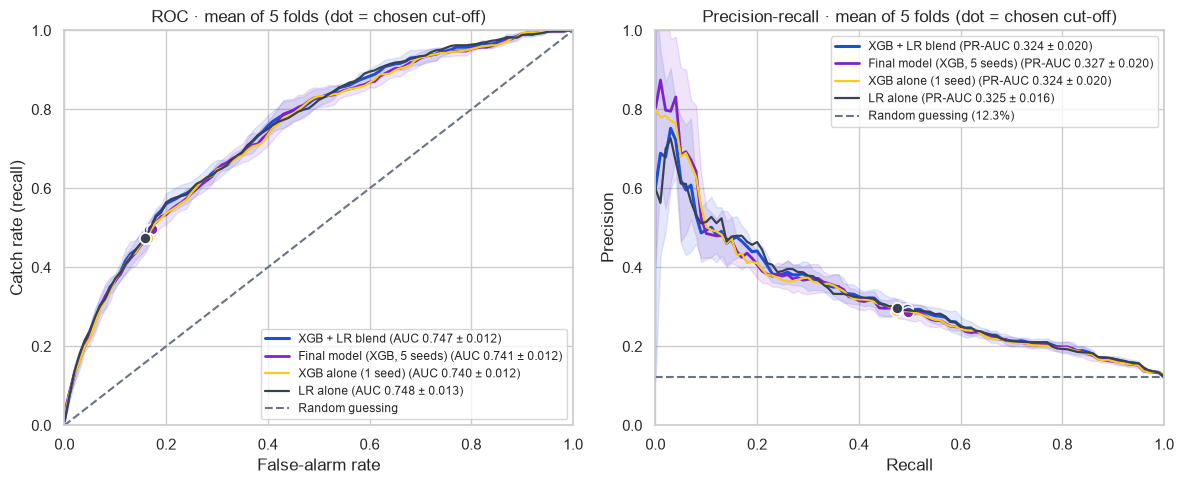

XGB + LR blend               at 20% false alarms catches 56.1% | at 50% recall precision 29.4% | cut-off dot: catch 49.4%, false alarms 16.6%, precision 29.5%
Final model (XGB, 5 seeds)   at 20% false alarms catches 53.3% | at 50% recall precision 28.6% | cut-off dot: catch 49.6%, false alarms 17.2%, precision 28.7%
XGB alone (1 seed)           at 20% false alarms catches 53.7% | at 50% recall precision 28.9% | cut-off dot: catch 47.3%, false alarms 16.4%, precision 28.9%
LR alone                     at 20% false alarms catches 56.4% | at 50% recall precision 29.1% | cut-off dot: catch 47.5%, false alarms 15.9%, precision 29.7%


In [8]:
GRID = np.linspace(0, 1, 101)
STYLE = {"blend": dict(color=BLUE, lw=2.2, band=True), "final": dict(color=PURPLE, lw=2, band=True),
         "xgb1": dict(color=YELLOW, lw=1.6, band=False), "lr": dict(color="#374151", lw=1.6, band=False)}

def fold_curves(k):
    rocs, prs, roc_dot, pr_dot = [], [], [], []
    for (_, te), t in zip(outer_splits, fold_thr[k]):
        yt, pt = y.iloc[te].to_numpy(), oof[k][te]
        fpr, tpr, _ = roc_curve(yt, pt)
        rocs.append(np.interp(GRID, fpr, tpr))
        prec, rec, _ = precision_recall_curve(yt, pt)
        prs.append(np.interp(GRID, rec[::-1], prec[::-1]))
        flag = pt >= t
        roc_dot.append((flag[yt == 0].mean(), flag[yt == 1].mean()))
        pr_dot.append((flag[yt == 1].mean(), yt[flag].mean() if flag.any() else 0.0))
    return np.array(rocs), np.array(prs), np.mean(roc_dot, axis=0), np.mean(pr_dot, axis=0)

curves = {k: fold_curves(k) for k in MODELS}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, (rocs, prs, roc_dot, pr_dot) in curves.items():
    st = STYLE[k]
    for ax, arr, dot, key, name in [(axes[0], rocs, roc_dot, "roc_auc", "AUC"), (axes[1], prs, pr_dot, "pr_auc", "PR-AUC")]:
        m, s = arr.mean(0), arr.std(0)
        ax.plot(GRID, m, color=st["color"], lw=st["lw"], label=f"{MODELS[k]} ({name} {fmt(scores[k][key])})")
        if st["band"]:
            ax.fill_between(GRID, m - s, m + s, color=st["color"], alpha=0.12)
        ax.plot(*dot, "o", color=st["color"], ms=8, mec="white", mew=1.2)
axes[0].plot(GRID, GRID, "--", color=GREY, label="Random guessing")
axes[1].plot(GRID, np.full_like(GRID, y.mean()), "--", color=GREY, label=f"Random guessing ({y.mean():.1%})")
axes[0].set(xlabel="False-alarm rate", ylabel="Catch rate (recall)", title="ROC · mean of 5 folds (dot = chosen cut-off)",
            xlim=(0, 1), ylim=(0, 1))
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall · mean of 5 folds (dot = chosen cut-off)",
            xlim=(0, 1), ylim=(0, 1))
axes[0].legend(loc="lower right", fontsize=8.5)
axes[1].legend(loc="upper right", fontsize=8.5)
save("02_roc_pr_blend")

for k, (rocs, prs, roc_dot, pr_dot) in curves.items():
    print(f"{MODELS[k]:28} at 20% false alarms catches {rocs[:, 20].mean():.1%} | at 50% recall precision "
          f"{prs[:, 50].mean():.1%} | cut-off dot: catch {roc_dot[1]:.1%}, false alarms {roc_dot[0]:.1%}, "
          f"precision {pr_dot[1]:.1%}")

## Step 8: The final blend (trained on all 5,000 employees)

1. **XGB part:** exactly xgboost_final's Step 8: switches by a 3-of-5 vote, one more Optuna search (300 trials) on all
   the data, 5-seed averaging. Its own F1-best cut-off should be xgboost_final's **0.6129**.
2. **LR part:** fitted on all the data.
3. **Blend:** Platt scaling, weight and F1-best cut-off from 5-fold (`CUTOFF_CV`) predictions on all the data.
   **Use this cut-off only with this blend.**

In [9]:
SWITCHES = ["impute", "add_indicator", "native_cat"] + CLUES
votes = {s: sum(bool(p.get(s, False)) for p in fold_params) for s in SWITCHES}
final_switches = {s: n >= 3 for s, n in votes.items()}
if not final_switches["impute"]:
    final_switches.pop("add_indicator")

t0 = time.time()
final_study = tune_xgb(X, y, fixed=final_switches)
final_params = {**final_study.best_params, **final_switches}
xgb_final = SeedAvgXGB(final_params)
xgb_all_oof = inner_oof(xgb_final, X, y, CUTOFF_CV)
lr_all_oof = inner_oof(LR, X, y, CUTOFF_CV)
xgb_part_thr = best_threshold(y, xgb_all_oof)
final_blend = fit_blend(y, xgb_all_oof, lr_all_oof)
final_thr = final_blend["thr"]
xgb_final.fit(X, y)
lr_final = clone(LR).fit(X, y)
print(f"Final blend: {(time.time() - t0) / 60:.1f} min\n")

print("Switches ON: ", [s for s, v in final_switches.items() if v])
print("Switches OFF:", [s for s, v in final_switches.items() if not v])
print("\nXGBoost settings (XGB part):")
for k, v in final_study.best_params.items():
    print(f"  {k:18} {round(v, 5) if isinstance(v, float) else v}")
print(f"  {'copies (seeds)':18} {N_SEEDS}")
print(f"\nXGB part's own cut-off: {xgb_part_thr:.4f} (xgboost_final: 0.6129)")
print(f"BLEND WEIGHT: {final_blend['w']} on XGBoost, {1 - final_blend['w']:.2f} on LR")
print(f"FINAL CUT-OFF: {final_thr:.4f} → flag as 'will leave' if blended chance ≥ {final_thr:.1%}")

p_all = blend_predict(final_blend, xgb_final.predict_proba(X)[:, 1], lr_final.predict_proba(X)[:, 1])
train_auc, train_f1 = roc_auc_score(y, p_all), f1_score(y, (p_all >= final_thr).astype(int))
print("\nOverfitting check          ROC-AUC    F1")
print(f"  seen (training data)     {train_auc:.3f}    {train_f1:.3f}")
print(f"  unseen (nested CV)       {scores['blend']['roc_auc'].mean():.3f}    {scores['blend']['f1'].mean():.3f}")
print(f"  gap                      {train_auc - scores['blend']['roc_auc'].mean():+.3f}   "
      f"{train_f1 - scores['blend']['f1'].mean():+.3f}")

Final blend: 1.5 min

Switches ON:  ['impute', 'add_indicator', 'native_cat', 'ot_x_dissat', 'tenure_bucket', 'sat_x_perf']
Switches OFF: ['salary_vs_level', 'salary_vs_dept', 'tenure_ratio']

XGBoost settings (XGB part):
  n_estimators       250
  learning_rate      0.01655
  max_depth          2
  min_child_weight   19
  subsample          0.89185
  colsample_bytree   0.56484
  gamma              0.08927
  reg_alpha          0.00224
  reg_lambda         0.17055
  scale_pos_weight   6.80329
  max_delta_step     4
  copies (seeds)     5

XGB part's own cut-off: 0.6129 (xgboost_final: 0.6129)
BLEND WEIGHT: 0.2 on XGBoost, 0.80 on LR
FINAL CUT-OFF: 0.1736 → flag as 'will leave' if blended chance ≥ 17.4%

Overfitting check          ROC-AUC    F1
  seen (training data)     0.761    0.384
  unseen (nested CV)       0.747    0.368
  gap                      +0.014   +0.016


## Step 9: What drives the risk (SHAP for the XGB part, odds ratios for the LR part)

The blend is not one tree model, so it has no single SHAP explanation. Instead:
- **XGB part:** SHAP exactly as in xgboost_final: for each employee, how much each clue pushed the XGB risk up or
  down (log-odds), averaged over the 5 copies.
- **LR part:** coefficients and odds ratios. Numbers are scaled, so an odds ratio is the change in LR's odds of
  leaving for **+1 standard deviation**; for department / level it is the odds relative to an average category
  (one-hot without a dropped reference).

                                   mean |SHAP|  share                     direction
job satisfaction                        0.2498  22.1%  higher → LESS risk (ρ -0.97)
monthly salary                          0.2185  19.4%  higher → LESS risk (ρ -0.95)
overtime × dissatisfaction              0.1821  16.1%  higher → MORE risk (ρ +0.96)
satisfaction × performance              0.1517  13.4%  higher → LESS risk (ρ -0.95)
overtime hours per month                0.1253  11.1%  higher → MORE risk (ρ +0.92)
job level                               0.1024   9.1%                      category
years at company                        0.0452   4.0%  higher → LESS risk (ρ -0.93)
department                              0.0380   3.4%                      category
performance rating                      0.0078   0.7%  higher → LESS risk (ρ -0.85)
age                                     0.0041   0.4%  higher → MORE risk (ρ +0.09)
tenure bucket                           0.0030   0.3%  higher → LESS risk (ρ

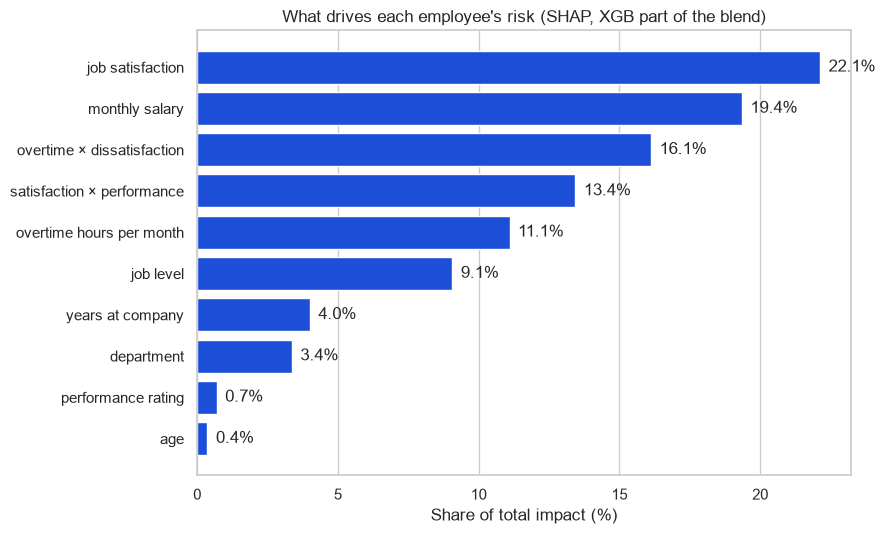

In [10]:
NICE = {"ot_x_dissat": "overtime × dissatisfaction", "salary_vs_level": "salary vs level median",
        "salary_vs_dept": "salary vs dept median", "tenure_ratio": "tenure ÷ age",
        "tenure_bucket": "tenure bucket", "sat_x_perf": "satisfaction × performance"}
def pretty(f):
    if f.startswith("missingindicator_"):
        return "blank: " + pretty(f.removeprefix("missingindicator_"))
    return NICE.get(f, f.replace("_", " "))

vals = []
for m in xgb_final.models_:
    Xt = m[:-1].transform(X)
    contrib = m.named_steps["model"].get_booster().predict(
        xgb.DMatrix(Xt, enable_categorical=True), pred_contribs=True)
    vals.append(pd.DataFrame(contrib[:, :-1], columns=Xt.columns, index=X.index))
sv = sum(vals) / len(vals)
groups = {c: next((t for t in text_cols if c.startswith(t + "_")), c) for c in sv.columns}
sv = sv.T.groupby(groups).sum().T
importance = sv.abs().mean().sort_values(ascending=False)

def direction(f):
    if f not in Xt.columns or Xt[f].dtype.kind not in "fi":
        return "category"
    v = Xt[f].to_numpy(dtype=float); ok = ~np.isnan(v)
    if np.ptp(sv[f].to_numpy()[ok]) == 0:
        return "never used"
    rho = spearmanr(v[ok], sv[f].to_numpy()[ok]).statistic
    return f"higher → {'MORE' if rho > 0 else 'LESS'} risk (ρ {rho:+.2f})"

shap_table = pd.DataFrame({"mean |SHAP|": importance.round(4),
                           "share": (importance / importance.sum()).map("{:.1%}".format),
                           "direction": [direction(f) for f in importance.index]})
shap_table.index = [pretty(f) for f in shap_table.index]
print(shap_table.to_string())

top = importance.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([pretty(f) for f in top.index], top / importance.sum() * 100, color=BLUE)
for i, v in enumerate(top / importance.sum() * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set(xlabel="Share of total impact (%)", title="What drives each employee's risk (SHAP, XGB part of the blend)")
ax.grid(axis="y", visible=False)
save("03_shap_drivers_blend")

In [11]:
lr_names = lr_final.named_steps["prep"].get_feature_names_out()
coef = lr_final.named_steps["model"].coef_[0]
lr_table = pd.DataFrame({"coefficient": coef.round(4), "odds ratio": np.exp(coef).round(3)},
                        index=[n.split("__", 1)[1].replace("_", " ") for n in lr_names])
lr_table = lr_table.reindex(lr_table["coefficient"].abs().sort_values(ascending=False).index)
print("LR part: coefficients and odds ratios (per +1 std for numbers)")
print(lr_table.to_string())

px, pl = final_blend["px"], final_blend["pl"]
print(f"\nBlend weight on XGBoost: {final_blend['w']}  |  on LR: {1 - final_blend['w']:.2f}")
print(f"Platt scaling, XGB part: rescaled logit = {px.coef_[0][0]:.3f} × logit(XGB chance) {px.intercept_[0]:+.3f}")
print(f"Platt scaling, LR part:  rescaled logit = {pl.coef_[0][0]:.3f} × logit(LR chance)  {pl.intercept_[0]:+.3f}")
print(f"\nSame drivers? XGB top 3 by SHAP: {', '.join(pretty(f) for f in importance.index[:3])} | "
      f"LR top 3 by |coefficient|: {', '.join(lr_table.index[:3])}")

LR part: coefficients and odds ratios (per +1 std for numbers)
                             coefficient  odds ratio
job satisfaction                 -0.4079       0.665
overtime hours per month          0.3739       1.453
department Marketing             -0.3665       0.693
job level Manager                -0.3083       0.735
monthly salary                   -0.2685       0.765
job level Entry                   0.2353       1.265
department Finance               -0.1814       0.834
job level Senior                 -0.1692       0.844
performance rating               -0.1219       0.885
department Fulfillment            0.1206       1.128
department Sales                  0.1196       1.127
years at company                 -0.1123       0.894
job level Mid                    -0.1041       0.901
department Technology            -0.0743       0.928
department Customer Service       0.0653       1.068
department Human Resources       -0.0516       0.950
department Supply Chain           0.

**How the two explanations combine.** For each employee the blend computes
`blended chance = w × Platt_XGB(XGB chance) + (1 − w) × Platt_LR(LR chance)`. The XGB SHAP values add up to the
XGB part's log-odds, and the LR coefficients add up to the LR part's log-odds. Each Platt step is a straight-line
rescaling of those log-odds (slope and intercept printed above), turned back into a chance. The blend then averages
the two **chances** with weight `w`, so a clue's total effect is roughly `w × (its rescaled XGB push) + (1 − w) ×
(its rescaled LR push)`, but not exactly. Averaging happens on the chance scale, not the log-odds scale, so the pushes
don't add up precisely. Read the two parts together: a clue that matters in both (e.g. job satisfaction) drives the
blend; a clue that matters in only one is diluted by the other part's weight.

## Step 10: Choosing a cut-off by HR's cost

F1 treats a missed leaver and a false alarm about equally. HR usually doesn't.
**Cost = missed leavers × C + false alarms**, where C = how many times worse a miss is.
Each fold's cut-off is chosen on its **training** (inner) predictions to minimise cost, then applied to its test part.
The same table is shown for the final model, computed the same way, for comparison.

In [12]:
def cost_cutoff(y_true, p, C):
    cands = np.unique(np.r_[p, 1.0 + 1e-9])
    costs = [((p < t) & (y_true == 1)).sum() * C + ((p >= t) & (y_true == 0)).sum() for t in cands]
    return float(cands[int(np.argmin(costs))])

def cost_table(k):
    rows = []
    for C in [3, 5, 10]:
        missed = fa = 0
        cuts = []
        for (tr, te), r in zip(outer_splits, runs):
            t = cost_cutoff(y.iloc[tr].to_numpy(), r["inner"][k], C)
            cuts.append(t)
            yt, pt = y.iloc[te].to_numpy(), oof[k][te]
            missed += int(((pt < t) & (yt == 1)).sum())
            fa += int(((pt >= t) & (yt == 0)).sum())
        rows.append({"C (miss costs C× a false alarm)": C, "missed": missed, "false alarms": fa,
                     "total cost": missed * C + fa, "flag nobody": int(y.sum()) * C,
                     "mean cut-off (fold scale)": round(np.mean(cuts), 3)})
    return pd.DataFrame(rows)

cost_df = cost_table("blend")
print("XGB + LR blend")
print(cost_df.to_string(index=False))
print("\nFinal model (same method)")
print(cost_table("final").to_string(index=False))
print("\nThe more a lost employee costs, the LOWER the cut-off should be (flag more people).")

XGB + LR blend
 C (miss costs C× a false alarm)  missed  false alarms  total cost  flag nobody  mean cut-off (fold scale)
                               3     450           274        1624         1839                      0.274
                               5     289           796        2241         3065                      0.170
                              10     130          1989        3289         6130                      0.095

Final model (same method)


 C (miss costs C× a false alarm)  missed  false alarms  total cost  flag nobody  mean cut-off (fold scale)
                               3     410           384        1614         1839                      0.289
                               5     285           863        2288         3065                      0.210
                              10     123          2056        3286         6130                      0.127

The more a lost employee costs, the LOWER the cut-off should be (flag more people).


## Step 11: Summary and saved model

The final blend is saved to `final_model_blend.joblib` with its weight, Platt scalers and cut-off.
To load it later, run Steps 1 and 4 first (they define the model classes and `blend_predict`), then:

```python
bundle = joblib.load("final_model_blend.joblib")
b = {"w": bundle["weight"], "px": bundle["platt_xgb"], "pl": bundle["platt_lr"]}
risk = blend_predict(b, bundle["xgb"].predict_proba(new_employees)[:, 1],
                     bundle["lr"].predict_proba(new_employees)[:, 1])
flag = risk >= bundle["cutoff"]
```

In [13]:
joblib.dump({"xgb": xgb_final, "lr": lr_final, "platt_xgb": final_blend["px"], "platt_lr": final_blend["pl"],
             "weight": final_blend["w"], "cutoff": final_thr, "params": final_params,
             "columns": list(X.columns)}, "final_model_blend.joblib")
tn, fp, fn, tp = pooled_cm("blend")

print("=" * 66)
print("FINAL MODEL · XGBoost (5 seeds) + Logistic Regression blend · nested 5-fold CV")
print("=" * 66)
for m, lab in zip(METRICS, METRIC_LABELS):
    print(f"  {lab:10} {fmt(scores['blend'][m])}")
print(f"  {'Fold cut-offs':10} {[round(t, 3) for t in fold_thr['blend']]} (mean {np.mean(fold_thr['blend']):.3f})")
print(f"  {'Fold weights':10} {fold_w} (weight on XGBoost)")
print(f"\n  Caught {tp} / {tp + fn} leavers | false alarms {fp} | missed {fn}")
print(f"  Final blend: weight {final_blend['w']} on XGBoost, cut-off {final_thr:.4f}")
print(f"  Top 3 drivers (XGB part, SHAP): {', '.join(pretty(f) for f in importance.index[:3])}")
print(f"  Top 3 drivers (LR part, |coef|): {', '.join(lr_table.index[:3])}")
print(f"\n  Saved: final_model_blend.joblib | charts in {OUT}/: {sorted(os.listdir(OUT))}")
print(f"  Total runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

FINAL MODEL · XGBoost (5 seeds) + Logistic Regression blend · nested 5-fold CV
  Accuracy   0.792 ± 0.014
  Precision  0.295 ± 0.017
  Recall     0.494 ± 0.044
  F1         0.368 ± 0.017
  ROC-AUC    0.747 ± 0.012
  PR-AUC     0.324 ± 0.020
  Fold cut-offs [0.194, 0.175, 0.161, 0.188, 0.169] (mean 0.177)
  Fold weights [0.1, 0.4, 1.0, 0.0, 0.4] (weight on XGBoost)

  Caught 303 / 613 leavers | false alarms 728 | missed 310
  Final blend: weight 0.2 on XGBoost, cut-off 0.1736
  Top 3 drivers (XGB part, SHAP): job satisfaction, monthly salary, overtime × dissatisfaction
  Top 3 drivers (LR part, |coef|): job satisfaction, overtime hours per month, department Marketing

  Saved: final_model_blend.joblib | charts in charts_xgb_blend/: ['01_confusion_matrix_blend.png', '02_roc_pr_blend.png', '03_shap_drivers_blend.png']
  Total runtime: 3.7 min
